# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170268         # <-- your full roll number
NAME = "Gitansh"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170268   Name: Gitansh   Fingerprint: 1C91C5F6   Tickets: 15

Ticket_ID                                                                           Ticket_Text
      T01                           Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
      T02                                           The state-of-the-art lab (Lab-3) is closed.
      T03               E-mail stopped responding during the lab. It works on another computer.
      T04                                                 Nothing works and nobody has replied.
      T05                   I tried restarting the VPN on my laptop. Is there another solution?
      T06                                    The projector keeps disconnecting. This is urgent.
      T07                           The printer keeps disconnecting. I don't know what changed.
      T08              VPN keeps disconnecting after restarting the system. Can you check this?
      T09 Student portal failed to open after restarting 

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
rows = []
details = {}

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    details[row["Ticket_ID"]] = result
    rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "sentences": len(result["sentences"]),
        "tokens": len(result["tokens"]),
        "punctuation": len(result["punct"]),
        "stopwords": len(result["stops"]),
        "unique_tokens": len(set(result["tokens"])),
        "final_tokens": len(result["final"])
    })

table = pd.DataFrame(rows)
total = {"Ticket_ID": "TOTAL"}
for col in ["sentences", "tokens", "punctuation", "stopwords", "final_tokens"]:
    total[col] = table[col].sum()
total["unique_tokens"] = len(set(t for r in details.values() for t in r["tokens"]))
table = pd.concat([table, pd.DataFrame([total])], ignore_index=True)
display(table)

ticket_id = FOCUS[0] if FOCUS else df.iloc[0]["Ticket_ID"]
print("selected ticket:", ticket_id)
print("text:", df.loc[df["Ticket_ID"] == ticket_id, "Ticket_Text"].iloc[0])
print("tokens:", details[ticket_id]["tokens"])
print("punctuation tokens:", details[ticket_id]["punct"])
print("stopwords:", details[ticket_id]["stops"])
print("final tokens:", details[ticket_id]["final"])

,Ticket_ID,sentences,tokens,punctuation,stopwords,unique_tokens,final_tokens
0,T01,1,9,2,2,9,5
1,T02,1,9,3,2,9,4
2,T03,2,13,2,4,12,7
3,T04,1,7,1,2,7,4
4,T05,2,14,2,6,14,6
5,T06,2,9,2,3,8,4
6,T07,2,12,2,4,11,6
7,T08,2,13,2,5,13,6
8,T09,2,15,2,5,15,8
9,T10,2,10,2,4,10,4


selected ticket: T06
text: The projector keeps disconnecting. This is urgent.
tokens: ['the', 'projector', 'keeps', 'disconnecting', '.', 'this', 'is', 'urgent', '.']
punctuation tokens: ['.', '.']
stopwords: ['the', 'this', 'is']
final tokens: ['projector', 'keeps', 'disconnecting', 'urgent']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]


import re

raw_tickets = df["Ticket_Text"].tolist()
texts = raw_tickets + TEST_LINES

patterns = {
    "words_longer_than_5": r"\b[A-Za-z]{6,}\b",
    "numbers": r"(?<![A-Za-z])\d+(?:[.,]\d+)*(?![A-Za-z])",
    "capitalized_words": r"\b[A-Z][a-zA-Z]*\b",
    "vowel_start_words": r"\b[aeiouAEIOU][a-zA-Z]*\b"
}

for i, text in enumerate(texts, 1):
    print(f"Text {i}: {text}")
    for name, pattern in patterns.items():
        print(name, re.findall(pattern, text))

    print("replaced:", re.sub(
        r"(?i)\b(?:[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,})\b|https?://[^\s]+|www\.[^\s]+|(?<!\w)(?:\+?\d{1,3}[ -]?)?(?:\(?\d{2,5}\)?[ -]?)?\d{3,5}[ -]\d{3,5}(?!\w)",
        lambda m: "<EMAIL>" if "@" in m.group() else "<URL>" if "://" in m.group().lower() or m.group().lower().startswith("www.") else "<PHONE>",
        text
    ))
    print()


Text 1: Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
words_longer_than_5 ['helpdesk', 'thapar', 'thapar']
numbers []
capitalized_words ['Write']
vowel_start_words ['it', 'edu', 'or', 'edu', 'it']
replaced: Write to <EMAIL> or visit <URL>

Text 2: The state-of-the-art lab (Lab-3) is closed.
words_longer_than_5 ['closed']
numbers ['3']
capitalized_words ['The', 'Lab']
vowel_start_words ['of', 'art', 'is']
replaced: The state-of-the-art lab (Lab-3) is closed.

Text 3: E-mail stopped responding during the lab. It works on another computer.
words_longer_than_5 ['stopped', 'responding', 'during', 'another', 'computer']
numbers []
capitalized_words ['E', 'It']
vowel_start_words ['E', 'It', 'on', 'another']
replaced: E-mail stopped responding during the lab. It works on another computer.

Text 4: Nothing works and nobody has replied.
words_longer_than_5 ['Nothing', 'nobody', 'replied']
numbers []
capitalized_words ['Nothing']
vowel_start_words ['and']
replaced: Nothing works and

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:
from nltk.tokenize import RegexpTokenizer

token_pattern = r"https?://[^\\s]+|www\\.[^\\s]+|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\\.[A-Za-z]{2,}|\\+?\\d[\\d ()-]{6,}\\d|\\d+(?:\\.\\d+)+|\\d+(?:,\\d{3})+|[A-Za-z]+(?:'[A-Za-z]+)?(?:-[A-Za-z]+(?:'[A-Za-z]+)?)*|\\d+|[^\\w\\s]"
tokenizer = RegexpTokenizer(token_pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

print("TEST_LINES:")
for line in TEST_LINES:
    print("custom:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))
    print()

different = 0
for _, row in df.iterrows():
    custom = my_tokenize(row["Ticket_Text"])
    normal = word_tokenize(row["Ticket_Text"])
    if custom != normal:
        different += 1

print("tickets tokenized differently:", different, "out of", len(df))

TEST_LINES:
custom: ['Mail', ' ', 'it', '.', 'helpdesk', '@', 'thapar', '.', 'edu', ' ', 'or', ' ', 'a', '.', 'b-c', '@', 'dept', '.', 'univ', '.', 'ac', '.', 'in', ';', ' ', 'visit', ' ', 'https://lm', 's', '.', 'thapar', '.', 'edu', '/', 'help', ' ', 'or', ' ', 'www', '.', 'thapar', '.', 'edu', '/', 'it', '.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

custom: ['Call', ' ', '+', '9', '1', ' ', '9', '8', '7', '6', '5', ' ', '4', '3', '2', '1', '0', ',', ' ', '+', '9', '1', '-', '9', '8', '7', '6', '5', '-', '4', '3', '2', '1', '0', ' ', 'or', ' ', '0', '1', '7', '5', '-', '2', '3', '9', '-', '3', '2', '0', '1', '.', ' ', 'Version', ' ', '2', '.', '0', '.', '1', ' ', 'is', ' ', '9', '5', '.', '5', '%', ' ', 'done', ';', ' ', 'fee', ' ', 'Rs', ' ', '1', ',', '2', '5', '0', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210',

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [9]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()
reg = RegexpStemmer("ing$", min=5)
lemmatizer = WordNetLemmatizer()

def wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("N"):
        return "n"
    if tag.startswith("R"):
        return "r"
    return "n"

words = sorted(set(token for result in details.values() for token in result["final"]))
tagged = dict(pos_tag(words))
rows = []

for word in words:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = reg.stem(word)
    lemma = lemmatizer.lemmatize(word, wordnet_pos(tagged.get(word, "NN")))
    if len({p, l, r, lemma}) > 1:
        rows.append({
            "word": word,
            "porter": p,
            "lancaster": l,
            "regexp": r,
            "lemmatizer": lemma
        })

print("Regexp suffix chosen: ing$ (for example, 'working' and 'uploading' lose the -ing suffix).")
display(pd.DataFrame(rows, columns=["word", "porter", "lancaster", "regexp", "lemmatizer"]))

Regexp suffix chosen: ing$ (for example, 'working' and 'uploading' lose the -ing suffix).


,word,porter,lancaster,regexp,lemmatizer
0,another,anoth,anoth,another,another
1,changed,chang,chang,changed,change
2,closed,close,clos,closed,close
3,computer,comput,comput,computer,computer
4,failed,fail,fail,failed,fail
5,hours,hour,hour,hours,hour
6,keeps,keep,keep,keeps,keep
7,mobile,mobil,mobl,mobile,mobile
8,nobody,nobodi,nobody,nobody,nobody
9,nothing,noth,noth,noth,nothing


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,set,total_tokens,unique_tokens,TTR
0,S1,171,81,0.473684
1,S2,142,76,0.535211
2,S3,83,53,0.638554
3,S4,83,52,0.626506


top 10 words in S1:
[('.', 20), ('the', 10), ('this', 7), ('is', 6), ('?', 6), ('keeps', 6), ('disconnecting', 5), ('after', 4), ('can', 4), ('you', 4)]
top 10 words in S3:
[('keeps', 6), ('disconnecting', 5), ('check', 4), ('another', 3), ('restarting', 3), ('urgent', 3), ('printer', 3), ('lab', 2), ('works', 2), ('vpn', 2)]


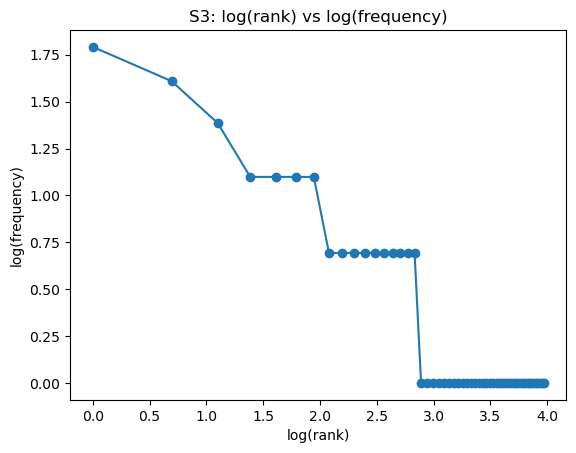

top 5 bigrams in S1:
[(('keeps', 'disconnecting'), 5), (('.', 'the'), 4), (('.', 'can'), 4), (('can', 'you'), 4), (('you', 'check'), 4)]
top 5 bigrams in S3:
[(('keeps', 'disconnecting'), 5), (('another', 'solution'), 2), (('printer', 'keeps'), 2), (('restarting', 'system'), 2), (('student', 'portal'), 2)]


In [10]:
from collections import Counter
from nltk.util import bigrams
import matplotlib.pyplot as plt
import numpy as np

s1 = [token for result in details.values() for token in result["tokens"]]
s2 = [token for result in details.values() for token in result["tokens"] if not is_punct(token)]
s3 = [token for result in details.values() for token in result["final"]]
s4 = [porter.stem(token) for token in s3]

stats = []
for name, seq in [("S1", s1), ("S2", s2), ("S3", s3), ("S4", s4)]:
    stats.append({
        "set": name,
        "total_tokens": len(seq),
        "unique_tokens": len(set(seq)),
        "TTR": len(set(seq)) / len(seq) if seq else 0
    })

display(pd.DataFrame(stats))

print("top 10 words in S1:")
print(Counter(s1).most_common(10))
print("top 10 words in S3:")
print(Counter(s3).most_common(10))

freq = Counter(s3)
ranked = sorted(freq.values(), reverse=True)
ranks = range(1, len(ranked) + 1)
plt.plot(np.log(ranks), np.log(ranked), marker="o")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("S3: log(rank) vs log(frequency)")
plt.show()

print("top 5 bigrams in S1:")
print(Counter(bigrams(s1)).most_common(5))
print("top 5 bigrams in S3:")
print(Counter(bigrams(s3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR decreases from S1 to S4 because stemming converts similar words into a common root form, reducing the number of unique tokens while the total number of tokens remains the same.